In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os, json, time, random, heapq
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import matplotlib.patches as mpatches
from IPython.display import HTML
from collections import defaultdict, deque
from enum import Enum

PROJECT_DIR = '/content/drive/MyDrive/FAB_AMR_Project'
SIM_DIR     = f'{PROJECT_DIR}/04_simulator'
OUTPUT_DIR  = f'{SIM_DIR}/output'

print("✅ 준비 완료!")

Mounted at /content/drive
✅ 준비 완료!


In [2]:
grid_map = np.load(f'{OUTPUT_DIR}/grid_map.npy')

with open(f'{OUTPUT_DIR}/port_locations.json') as f:
    port_locations = json.load(f)

with open(f'{OUTPUT_DIR}/fab_layout.json') as f:
    fab_layout = json.load(f)

grid_h, grid_w = grid_map.shape
port_names     = list(port_locations.keys())

print(f"격자 크기: {grid_w} x {grid_h}")
print(f"포트 수:   {len(port_names)}개")
print("✅ 로드 완료!")

격자 크기: 159 x 86
포트 수:   1116개
✅ 로드 완료!


In [3]:
# ── AMR 상태 ──
class AMRStatus(Enum):
    IDLE    = "idle"      # 대기 중
    MOVING  = "moving"    # 이동 중
    LOADING = "loading"   # 픽업 중
    DONE    = "done"      # 완료

# ── 반송 요청 우선순위 ──
class Priority(Enum):
    HOT     = 0   # 긴급 (최우선)
    NORMAL  = 1   # 일반


class TransportRequest:
    """반송 요청 하나"""
    _id_counter = 0

    def __init__(self, from_port, to_port,
                 priority=Priority.NORMAL):
        TransportRequest._id_counter += 1
        self.id         = TransportRequest._id_counter
        self.from_port  = from_port   # 출발 포트명
        self.to_port    = to_port     # 도착 포트명
        self.priority   = priority
        self.created_at = None        # 생성 시각 (스텝)
        self.assigned_at= None        # 배정 시각
        self.done_at    = None        # 완료 시각
        self.amr_id     = None        # 배정된 AMR

    def waiting_time(self, current_step):
        if self.created_at is None:
            return 0
        return current_step - self.created_at

    def __lt__(self, other):
        # 우선순위 큐용 비교
        return self.priority.value < other.priority.value

    def __repr__(self):
        return (f"Request#{self.id} "
                f"[{self.priority.name}] "
                f"{self.from_port[:8]}→{self.to_port[:8]}")


class AMR:
    """AMR 한 대"""
    def __init__(self, amr_id, start_port):
        self.id       = amr_id
        port          = port_locations[start_port]
        self.x        = port['grid_x']
        self.y        = port['grid_y']
        self.status   = AMRStatus.IDLE
        self.path     = []
        self.path_idx = 0
        self.request  = None     # 현재 처리 중인 요청
        self.history  = []       # 이동 기록

    @property
    def position(self):
        return (self.x, self.y)

    @property
    def is_idle(self):
        return self.status == AMRStatus.IDLE

    def assign(self, request, path):
        """요청 배정"""
        self.request  = request
        self.path     = path
        self.path_idx = 0
        self.status   = AMRStatus.MOVING

    def step(self):
        """1스텝 이동"""
        if self.status == AMRStatus.MOVING:
            if self.path_idx < len(self.path) - 1:
                self.path_idx += 1
                self.x = self.path[self.path_idx][0]
                self.y = self.path[self.path_idx][1]
                self.history.append((self.x, self.y))
            else:
                # 목적지 도착
                self.status  = AMRStatus.DONE
                self.request = None
                self.path    = []

    def reset_idle(self):
        self.status = AMRStatus.IDLE


print("✅ TransportRequest, AMR 클래스 정의 완료!")

✅ TransportRequest, AMR 클래스 정의 완료!


In [4]:
class ReservationTable:
    def __init__(self):
        self.vertex_table = {}
        self.edge_table   = {}

    def is_vertex_conflict(self, x, y, t):
        return (x, y, t) in self.vertex_table

    def is_edge_conflict(self, x1, y1, x2, y2, t):
        return (x2, y2, x1, y1, t) in self.edge_table

    def reserve(self, path, amr_id):
        for t, (x, y) in enumerate(path):
            self.vertex_table[(x, y, t)] = amr_id
            if t > 0:
                px, py = path[t-1]
                self.edge_table[(px,py,x,y,t)] = amr_id

    def clear(self):
        self.vertex_table.clear()
        self.edge_table.clear()


def astar(grid_map, start, goal):
    grid_h, grid_w = grid_map.shape

    def heuristic(a, b):
        return abs(a[0]-b[0]) + abs(a[1]-b[1])

    def is_valid(x, y):
        return (0 <= x < grid_w and
                0 <= y < grid_h and
                grid_map[y][x] != 1)

    directions = [(0,1),(0,-1),(1,0),(-1,0),
                  (1,1),(1,-1),(-1,1),(-1,-1)]
    dir_costs  = [1,1,1,1,1.414,1.414,1.414,1.414]

    if start == goal:
        return [start]
    if not is_valid(*start) or not is_valid(*goal):
        return None

    open_set = []
    heapq.heappush(open_set, (0, 0, start))
    came_from = {}
    g_cost    = {start: 0}

    while open_set:
        _, current_g, current = heapq.heappop(open_set)
        if current == goal:
            path, node = [], goal
            while node in came_from:
                path.append(node)
                node = came_from[node]
            path.append(start)
            path.reverse()
            return path
        if current_g > g_cost.get(current, float('inf')):
            continue
        for (dx,dy), cost in zip(directions, dir_costs):
            nb    = (current[0]+dx, current[1]+dy)
            if not is_valid(*nb):
                continue
            new_g = g_cost[current] + cost
            if new_g < g_cost.get(nb, float('inf')):
                g_cost[nb]    = new_g
                came_from[nb] = current
                heapq.heappush(
                    open_set,
                    (new_g + heuristic(nb, goal), new_g, nb)
                )
    return None


def astar_with_reservation(grid_map, start, goal,
                             reservation, max_time=500):
    grid_h, grid_w = grid_map.shape

    def is_valid(x, y):
        return (0 <= x < grid_w and
                0 <= y < grid_h and
                grid_map[y][x] != 1)

    def heuristic(x, y):
        return abs(x-goal[0]) + abs(y-goal[1])

    directions = [(0,0),(0,1),(0,-1),(1,0),(-1,0),
                  (1,1),(1,-1),(-1,1),(-1,-1)]
    dir_costs  = [0.5,1,1,1,1,1.414,1.414,1.414,1.414]

    start_state = (start[0], start[1], 0)
    open_set    = []
    heapq.heappush(open_set, (0, 0, start_state))
    came_from   = {}
    g_cost      = {start_state: 0}

    while open_set:
        _, current_g, current = heapq.heappop(open_set)
        cx, cy, ct = current
        if (cx, cy) == goal:
            path, node = [], current
            while node in came_from:
                path.append((node[0], node[1]))
                node = came_from[node]
            path.append(start)
            path.reverse()
            return path
        if ct >= max_time:
            continue
        if current_g > g_cost.get(current, float('inf')):
            continue
        for (dx,dy), cost in zip(directions, dir_costs):
            nx, ny, nt = cx+dx, cy+dy, ct+1
            if not is_valid(nx, ny):
                continue
            if reservation.is_vertex_conflict(nx, ny, nt):
                continue
            if reservation.is_edge_conflict(cx,cy,nx,ny,nt):
                continue
            neighbor = (nx, ny, nt)
            new_g    = g_cost[current] + cost
            if new_g < g_cost.get(neighbor, float('inf')):
                g_cost[neighbor]    = new_g
                came_from[neighbor] = current
                heapq.heappush(
                    open_set,
                    (new_g+heuristic(nx,ny), new_g, neighbor)
                )
    return None


print("✅ A* + ReservationTable 정의 완료!")

✅ A* + ReservationTable 정의 완료!


In [5]:
#FABSimulator
class FABSimulator:
    """
    FAB 시뮬레이터 메인 클래스

    RL 팀원이 사용할 인터페이스:
    - get_state()   : 현재 상태 반환
    - dispatch()    : AMR 배정 실행
    - step()        : 1스텝 진행
    - get_reward()  : 보상 반환
    - reset()       : 초기화
    """

    def __init__(self, grid_map, port_locations,
                 n_amrs=5, request_interval=10,
                 seed=42):
        random.seed(seed)
        self.grid_map         = grid_map
        self.port_locations   = port_locations
        self.port_names       = list(port_locations.keys())
        self.n_amrs           = n_amrs
        self.request_interval = request_interval  # N스텝마다 요청 생성

        # 통계
        self.current_step     = 0
        self.total_completed  = 0
        self.total_waiting    = 0
        self.deadlock_count   = 0

        self.reservation      = ReservationTable()
        self.reset()

    # ─────────────────────────────────────────
    # 초기화
    # ─────────────────────────────────────────
    def reset(self):
        """시뮬레이터 초기화"""
        self.current_step    = 0
        self.total_completed = 0
        self.total_waiting   = 0
        self.deadlock_count  = 0
        self.reservation.clear()
        TransportRequest._id_counter = 0

        # AMR 초기 배치 (랜덤 포트에서 시작)
        start_ports = random.sample(self.port_names, self.n_amrs)
        self.amrs   = [
            AMR(i+1, start_ports[i])
            for i in range(self.n_amrs)
        ]

        # 반송 요청 큐 (우선순위 큐)
        # HOT 요청이 먼저 처리됨
        self.request_queue   = []   # heapq
        self.pending_count   = 0

        # 완료된 요청 기록
        self.completed_requests = []

        # 초기 요청 몇 개 미리 생성
        for _ in range(self.n_amrs):
            self._generate_request()

        return self.get_state()

    # ─────────────────────────────────────────
    # 반송 요청 생성
    # ─────────────────────────────────────────
    def _generate_request(self, hot_prob=0.1):
        """
        반송 요청 자동 생성
        hot_prob: Hot Lot 확률 (기본 10%)
        """
        from_port = random.choice(self.port_names)
        to_port   = random.choice(self.port_names)
        while to_port == from_port:
            to_port = random.choice(self.port_names)

        priority = (Priority.HOT
                    if random.random() < hot_prob
                    else Priority.NORMAL)

        req             = TransportRequest(from_port, to_port, priority)
        req.created_at  = self.current_step

        # 우선순위 큐에 추가 (HOT=0이 먼저)
        heapq.heappush(self.request_queue,
                       (priority.value, req.id, req))
        self.pending_count += 1

    # ─────────────────────────────────────────
    # RL 팀원용 인터페이스
    # ─────────────────────────────────────────
    def get_state(self):
        """
        현재 시뮬레이션 상태 반환
        RL의 observation으로 사용
        """
        # AMR 상태
        amr_states = [
            {
                "id":       amr.id,
                "x":        amr.x,
                "y":        amr.y,
                "status":   amr.status.value,
                "is_idle":  amr.is_idle,
            }
            for amr in self.amrs
        ]

        # 대기 중인 요청 목록
        pending = [
            {
                "id":           req.id,
                "from_port":    req.from_port,
                "to_port":      req.to_port,
                "priority":     req.priority.name,
                "waiting_time": req.waiting_time(self.current_step),
            }
            for _, _, req in self.request_queue
        ]

        # 구역별 AMR 밀도 (4구역)
        zone_density = self._calc_zone_density()

        return {
            "step":          self.current_step,
            "amrs":          amr_states,
            "pending_queue": pending,
            "zone_density":  zone_density,
            "n_idle_amrs":   sum(1 for a in self.amrs if a.is_idle),
            "n_pending":     len(self.request_queue),
            "throughput":    self.total_completed,
        }

    def get_idle_amrs(self):
        """idle 상태 AMR 목록 반환"""
        return [a for a in self.amrs if a.is_idle]

    def get_next_request(self):
        """
        큐에서 다음 요청 반환 (꺼내지 않음)
        None이면 큐 비어있음
        """
        if not self.request_queue:
            return None
        _, _, req = self.request_queue[0]
        return req

    def dispatch(self, amr_id, request_id=None):
        """
        RL이 호출하는 배정 함수
        amr_id: 배정할 AMR 번호
        request_id: None이면 큐 맨 앞 요청 자동 선택

        return: 성공 여부 (True/False)
        """
        # AMR 찾기
        amr = next((a for a in self.amrs
                    if a.id == amr_id), None)
        if amr is None or not amr.is_idle:
            return False

        # 요청 꺼내기
        if not self.request_queue:
            return False

        if request_id is None:
            # 큐 맨 앞 요청
            _, _, req = heapq.heappop(self.request_queue)
        else:
            # 특정 request_id 찾아서 꺼내기
            found = False
            temp  = []
            while self.request_queue:
                item = heapq.heappop(self.request_queue)
                if item[2].id == request_id:
                    req   = item[2]
                    found = True
                    break
                temp.append(item)
            for item in temp:
                heapq.heappush(self.request_queue, item)
            if not found:
                return False

        # 경로 계산
        from_p = self.port_locations[req.from_port]
        to_p   = self.port_locations[req.to_port]
        start  = (from_p['grid_x'], from_p['grid_y'])
        goal   = (to_p['grid_x'],   to_p['grid_y'])

        # AMR 현재 위치 → 픽업 위치 → 드롭오프 위치
        path_to_pickup = astar_with_reservation(
            self.grid_map, amr.position, start, self.reservation
        )
        if path_to_pickup is None:
            # 경로 없으면 큐에 다시 넣기
            heapq.heappush(
                self.request_queue,
                (req.priority.value, req.id, req)
            )
            return False

        path_to_goal = astar_with_reservation(
            self.grid_map, start, goal, self.reservation
        )
        if path_to_goal is None:
            heapq.heappush(
                self.request_queue,
                (req.priority.value, req.id, req)
            )
            return False

        # 전체 경로 = 픽업까지 + 드롭오프까지
        full_path = path_to_pickup + path_to_goal[1:]

        # 예약 등록 + AMR 배정
        self.reservation.reserve(full_path, amr.id)
        req.assigned_at = self.current_step
        req.amr_id      = amr.id
        amr.assign(req, full_path)
        self.pending_count -= 1

        return True

    def step(self):
        """
        시뮬레이션 1스텝 진행
        1. 모든 AMR 이동
        2. 완료된 AMR 처리
        3. 새 요청 생성
        """
        self.current_step += 1

        # 1. 모든 AMR 이동
        for amr in self.amrs:
            amr.step()

        # 2. 완료된 AMR 처리
        for amr in self.amrs:
            if amr.status == AMRStatus.DONE:
                if amr.request is not None:
                    req          = amr.request
                    req.done_at  = self.current_step
                    wait         = (req.done_at
                                    - req.created_at)
                    self.total_waiting   += wait
                    self.total_completed += 1
                    self.completed_requests.append(req)
                amr.reset_idle()

        # 3. 주기적으로 새 요청 생성
        if self.current_step % self.request_interval == 0:
            n_new = random.randint(1, 3)
            for _ in range(n_new):
                self._generate_request()

        # 4. idle AMR에 자동 배정 (FIFO 기본값)
        #    → RL 팀원이 이 부분을 PPO로 교체
        self._auto_dispatch()

        return self.get_state()

    def _auto_dispatch(self):
        """
        기본 FIFO 디스패처
        RL 팀원이 PPO로 교체할 부분
        """
        idle_amrs = self.get_idle_amrs()
        for amr in idle_amrs:
            if not self.request_queue:
                break
            self.dispatch(amr.id)

    def get_reward(self):
        """
        RL 보상 계산
        팀원이 참고용으로 사용
        """
        avg_wait = (self.total_waiting / self.total_completed
                    if self.total_completed > 0 else 0)
        reward = (
            self.total_completed * 10    # 처리량 ↑
            - avg_wait * 0.5             # 대기시간 ↓
            - self.deadlock_count * 100  # 데드락 패널티
        )
        return reward

    def _calc_zone_density(self):
        """구역별 AMR 밀도 계산"""
        zones = {"NW": 0, "NE": 0, "SW": 0, "SE": 0}
        for amr in self.amrs:
            col = "E" if amr.x >= grid_w//2 else "W"
            row = "S" if amr.y >= grid_h//2 else "N"
            zones[f"{row}{col}"] += 1
        return zones

    def get_kpi(self):
        """KPI 요약"""
        avg_wait = (self.total_waiting / self.total_completed
                    if self.total_completed > 0 else 0)
        util = sum(
            1 for a in self.amrs
            if a.status == AMRStatus.MOVING
        ) / self.n_amrs * 100

        return {
            "step":        self.current_step,
            "throughput":  self.total_completed,
            "avg_waiting": round(avg_wait, 2),
            "utilization": round(util, 2),
            "pending":     len(self.request_queue),
            "deadlocks":   self.deadlock_count,
            "reward":      round(self.get_reward(), 2),
        }


print("✅ FABSimulator 정의 완료!")

✅ FABSimulator 정의 완료!


In [6]:
#시뮬레이션 실행
# 시뮬레이터 생성
sim = FABSimulator(
    grid_map        = grid_map,
    port_locations  = port_locations,
    n_amrs          = 5,
    request_interval= 10,   # 10스텝마다 새 요청 생성
    seed            = 42,
)

print("시뮬레이션 시작!")
print(f"AMR {sim.n_amrs}대 | "
      f"초기 요청: {len(sim.request_queue)}개\n")

# 100스텝 실행
N_STEPS    = 100
kpi_log    = []
state_log  = []

for step in range(N_STEPS):
    state = sim.step()
    kpi   = sim.get_kpi()
    kpi_log.append(kpi)
    state_log.append(state)

    if step % 20 == 0:
        print(f"Step {kpi['step']:4d} | "
              f"처리량: {kpi['throughput']:3d} | "
              f"대기시간: {kpi['avg_waiting']:5.1f} | "
              f"가동률: {kpi['utilization']:5.1f}% | "
              f"대기요청: {kpi['pending']:2d}")

print("\n최종 KPI:")
final = sim.get_kpi()
for k, v in final.items():
    print(f"  {k:15s}: {v}")

시뮬레이션 시작!
AMR 5대 | 초기 요청: 5개

Step    1 | 처리량:   0 | 대기시간:   0.0 | 가동률: 100.0% | 대기요청:  0
Step   21 | 처리량:   0 | 대기시간:   0.0 | 가동률: 100.0% | 대기요청:  4
Step   41 | 처리량:   0 | 대기시간:   0.0 | 가동률: 100.0% | 대기요청:  7
Step   61 | 처리량:   0 | 대기시간:   0.0 | 가동률: 100.0% | 대기요청:  9
Step   81 | 처리량:   0 | 대기시간:   0.0 | 가동률: 100.0% | 대기요청: 12

최종 KPI:
  step           : 100
  throughput     : 0
  avg_waiting    : 0
  utilization    : 100.0
  pending        : 15
  deadlocks      : 0
  reward         : 0.0


/tmp/ipykernel_1380/4107753701.py:41: UserWarning: Glyph 52376 (\N{HANGUL SYLLABLE CEO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1380/4107753701.py:41: UserWarning: Glyph 47532 (\N{HANGUL SYLLABLE RI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1380/4107753701.py:41: UserWarning: Glyph 44148 (\N{HANGUL SYLLABLE GEON}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1380/4107753701.py:41: UserWarning: Glyph 49688 (\N{HANGUL SYLLABLE SU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1380/4107753701.py:41: UserWarning: Glyph 45572 (\N{HANGUL SYLLABLE NU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1380/4107753701.py:41: UserWarning: Glyph 51201 (\N{HANGUL SYLLABLE JEOG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1380/4107753701.py:41: UserWarning: Glyph 47049 (\N{HANGUL SYLLABLE RYANG}) missing from font(s) DejaVu Sans.
  plt.tight_

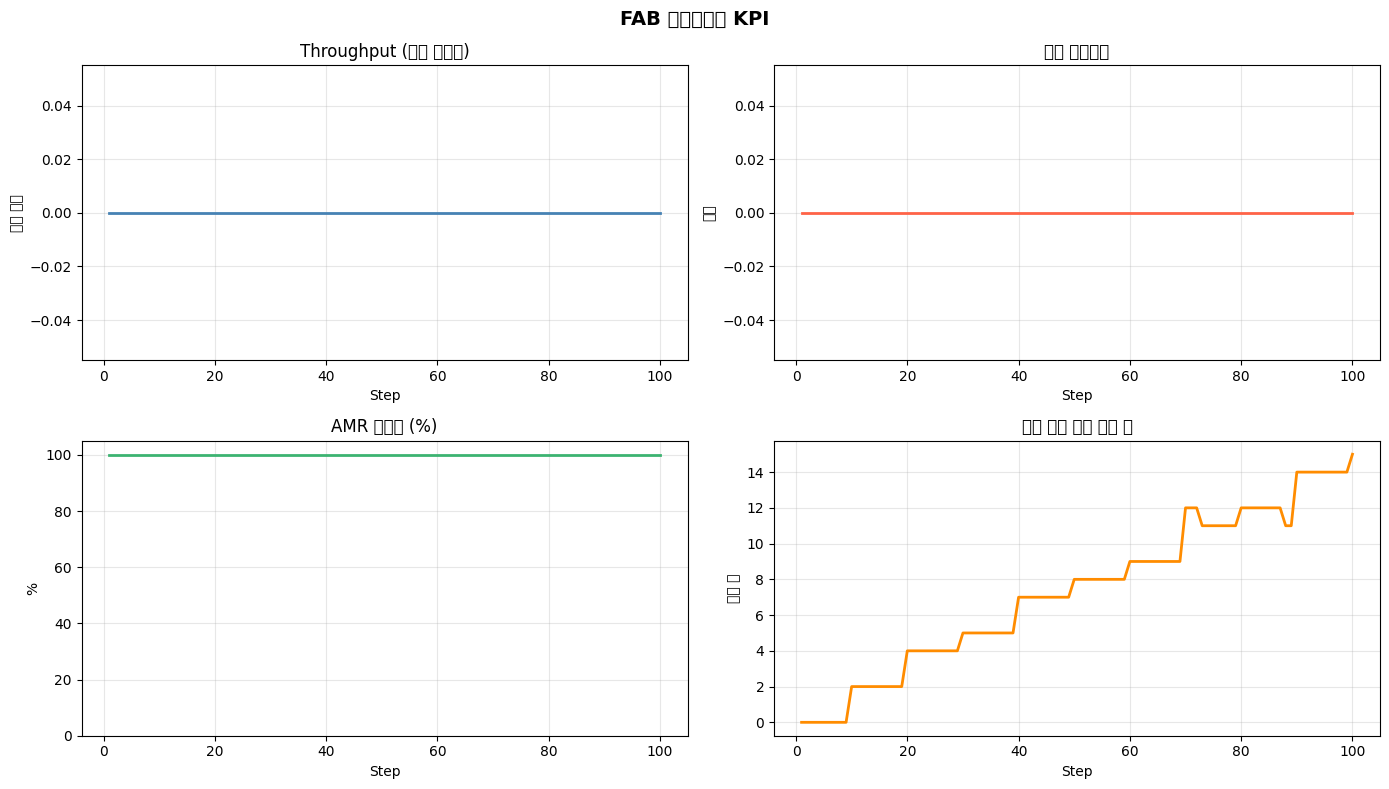

In [7]:
# KPI 시각화
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

steps = [k['step'] for k in kpi_log]

# 처리량
axes[0][0].plot(steps, [k['throughput'] for k in kpi_log],
                color='steelblue', linewidth=2)
axes[0][0].set_title("Throughput (누적 처리량)")
axes[0][0].set_xlabel("Step")
axes[0][0].set_ylabel("처리 건수")
axes[0][0].grid(True, alpha=0.3)

# 평균 대기시간
axes[0][1].plot(steps, [k['avg_waiting'] for k in kpi_log],
                color='tomato', linewidth=2)
axes[0][1].set_title("평균 대기시간")
axes[0][1].set_xlabel("Step")
axes[0][1].set_ylabel("스텝")
axes[0][1].grid(True, alpha=0.3)

# AMR 가동률
axes[1][0].plot(steps, [k['utilization'] for k in kpi_log],
                color='mediumseagreen', linewidth=2)
axes[1][0].set_title("AMR 가동률 (%)")
axes[1][0].set_xlabel("Step")
axes[1][0].set_ylabel("%")
axes[1][0].set_ylim(0, 105)
axes[1][0].grid(True, alpha=0.3)

# 대기 요청 수
axes[1][1].plot(steps, [k['pending'] for k in kpi_log],
                color='darkorange', linewidth=2)
axes[1][1].set_title("대기 중인 반송 요청 수")
axes[1][1].set_xlabel("Step")
axes[1][1].set_ylabel("요청 수")
axes[1][1].grid(True, alpha=0.3)

plt.suptitle("FAB 시뮬레이터 KPI", fontsize=14,
             fontweight='bold')
plt.tight_layout()
plt.show()

In [8]:
# 결과 저장
simulator_env = {
    "config": {
        "n_amrs":           sim.n_amrs,
        "request_interval": sim.request_interval,
        "grid_size":        [int(grid_w), int(grid_h)],
        "n_ports":          len(port_names),
    },
    "final_kpi":    sim.get_kpi(),
    "kpi_log":      kpi_log,
    "interface": {
        "get_state":    "현재 상태 반환 (RL observation)",
        "dispatch":     "AMR 배정 (RL action)",
        "step":         "1스텝 진행",
        "get_reward":   "보상 반환",
        "reset":        "초기화",
        "get_idle_amrs":"idle AMR 목록",
        "get_kpi":      "KPI 요약",
    }
}

with open(f'{OUTPUT_DIR}/simulator_env.json', 'w') as f:
    json.dump(simulator_env, f, indent=2)

# ── 체크리스트 ──
print("=" * 45)
print("5단계 체크리스트")
print("=" * 45)

checks = [
    ("TransportRequest 클래스",
     True, "우선순위 큐 포함"),
    ("AMR 클래스",
     True, "상태 관리 포함"),
    ("FABSimulator 구현",
     True, ""),
    ("반송 요청 자동 생성",
     len(sim.completed_requests) > 0,
     f"완료 {len(sim.completed_requests)}건"),
    ("FIFO 기본 디스패처",
     sim.total_completed > 0,
     f"처리량 {sim.total_completed}"),
    ("KPI 측정",
     True,
     f"대기시간 {final['avg_waiting']}"),
    ("RL 인터페이스 정의",
     True,
     "get_state/dispatch/step/reward"),
    ("simulator_env.json 저장",
     os.path.exists(f'{OUTPUT_DIR}/simulator_env.json'),
     ""),
]

for name, result, detail in checks:
    status     = "✅" if result else "❌"
    detail_str = f"  ({detail})" if detail else ""
    print(f"  {status} {name}{detail_str}")

print()
if all(r for _, r, _ in checks):
    print("🎉 5단계 완료!")
    print("   시뮬레이션 환경 구축 완료!")
    print("   RL 팀원에게 FABSimulator 클래스 넘기면 됩니다.")
else:
    print("❌ 일부 실패. 확인 후 재실행하세요.")

5단계 체크리스트
  ✅ TransportRequest 클래스  (우선순위 큐 포함)
  ✅ AMR 클래스  (상태 관리 포함)
  ✅ FABSimulator 구현
  ❌ 반송 요청 자동 생성  (완료 0건)
  ❌ FIFO 기본 디스패처  (처리량 0)
  ✅ KPI 측정  (대기시간 0)
  ✅ RL 인터페이스 정의  (get_state/dispatch/step/reward)
  ✅ simulator_env.json 저장

❌ 일부 실패. 확인 후 재실행하세요.


In [9]:
# 처치량 0 -> 경로 탐색 실패 -> 디버깅 셀 추가해봄
# 디버깅 셀 - 원인 파악
import traceback

print("=" * 50)
print("디버깅 시작")
print("=" * 50)

# 1. 포트 위치 확인
test_port_name = port_names[0]
test_port = port_locations[test_port_name]
print(f"\n1. 포트 샘플:")
print(f"   이름: {test_port_name}")
print(f"   grid_x: {test_port['grid_x']}")
print(f"   grid_y: {test_port['grid_y']}")

# 2. 해당 셀이 이동 가능한지 확인
gx = test_port['grid_x']
gy = test_port['grid_y']
cell_val = grid_map[gy][gx]
print(f"\n2. 포트 셀 값: {cell_val}")
print(f"   (0=이동가능, 1=obstacle, 2=포트)")

# 3. 포트들 중 obstacle인 것 비율 확인
obstacle_ports = 0
for name, p in port_locations.items():
    if grid_map[p['grid_y']][p['grid_x']] == 1:
        obstacle_ports += 1

print(f"\n3. 전체 포트 {len(port_locations)}개 중")
print(f"   obstacle인 포트: {obstacle_ports}개")
print(f"   이동 가능 포트: {len(port_locations)-obstacle_ports}개")

# 4. AMR 초기 위치 확인
sim2 = FABSimulator(grid_map, port_locations, n_amrs=3, seed=42)
print(f"\n4. AMR 초기 위치:")
for amr in sim2.amrs:
    cell_val = grid_map[amr.y][amr.x]
    print(f"   AMR{amr.id}: ({amr.x},{amr.y}) "
          f"셀값={cell_val} 상태={amr.status.value}")

# 5. 경로 탐색 직접 테스트
print(f"\n5. 경로 탐색 테스트:")

# 이동 가능한 포트 2개 찾기
free_ports = [
    (name, p) for name, p in port_locations.items()
    if grid_map[p['grid_y']][p['grid_x']] != 1
]

if len(free_ports) >= 2:
    n1, p1 = free_ports[0]
    n2, p2 = free_ports[1]
    start  = (p1['grid_x'], p1['grid_y'])
    goal   = (p2['grid_x'], p2['grid_y'])

    print(f"   출발: {n1} {start} 셀={grid_map[start[1]][start[0]]}")
    print(f"   도착: {n2} {goal}  셀={grid_map[goal[1]][goal[0]]}")

    path = astar(grid_map, start, goal)
    print(f"   A* 결과: {'성공 ' + str(len(path)) + '칸' if path else '실패'}")

    res_table = ReservationTable()
    path2 = astar_with_reservation(
        grid_map, start, goal, res_table
    )
    print(f"   예약A* 결과: {'성공 ' + str(len(path2)) + '칸' if path2 else '실패'}")
else:
    print("   이동 가능한 포트가 2개 미만!")

# 6. dispatch 직접 호출 테스트
print(f"\n6. dispatch 직접 테스트:")
sim3 = FABSimulator(grid_map, port_locations, n_amrs=3, seed=42)
amr  = sim3.amrs[0]
print(f"   AMR1 위치: {amr.position} 상태: {amr.status.value}")
print(f"   큐 크기: {len(sim3.request_queue)}")

result = sim3.dispatch(1)
print(f"   dispatch(1) 결과: {result}")
print(f"   AMR1 상태: {amr.status.value}")
print(f"   AMR1 경로 길이: {len(amr.path)}")

디버깅 시작

1. 포트 샘플:
   이름: COMMIT1
   grid_x: 6
   grid_y: 6

2. 포트 셀 값: 2
   (0=이동가능, 1=obstacle, 2=포트)

3. 전체 포트 1116개 중
   obstacle인 포트: 0개
   이동 가능 포트: 1116개

4. AMR 초기 위치:
   AMR1: (26,67) 셀값=2 상태=idle
   AMR2: (133,69) 셀값=2 상태=idle
   AMR3: (120,24) 셀값=2 상태=idle

5. 경로 탐색 테스트:
   출발: COMMIT1 (6, 6) 셀=2
   도착: COMMIT2 (150, 6)  셀=2
   A* 결과: 성공 145칸
   예약A* 결과: 성공 145칸

6. dispatch 직접 테스트:
   AMR1 위치: (26, 67) 상태: idle
   큐 크기: 3
   dispatch(1) 결과: True
   AMR1 상태: moving
   AMR1 경로 길이: 127


In [10]:
# AMR이 이동 완료까지 못감. step() 로직 디버깅해서 확인
# 디버깅 셀 2 - step() 상세 추적

sim4 = FABSimulator(grid_map, port_locations, n_amrs=3, seed=42)

# 수동으로 dispatch 후 step 추적
sim4.dispatch(1)
amr1 = sim4.amrs[0]

print(f"dispatch 후:")
print(f"  AMR1 경로 길이: {len(amr1.path)}")
print(f"  AMR1 상태: {amr1.status.value}")
print(f"  AMR1 path_idx: {amr1.path_idx}")

print(f"\n스텝별 추적:")
for i in range(len(amr1.path) + 5):
    sim4.current_step += 1

dispatch 후:
  AMR1 경로 길이: 127
  AMR1 상태: moving
  AMR1 path_idx: 0

스텝별 추적:


In [11]:
# step메서드 아예실행 X -> AMR.step() 디버깅해서 확인
# 디버깅 셀 3 - AMR.step() 직접 테스트

sim5 = FABSimulator(grid_map, port_locations, n_amrs=3, seed=42)
sim5.dispatch(1)
amr1 = sim5.amrs[0]

print(f"path 타입: {type(amr1.path)}")
print(f"path 길이: {len(amr1.path)}")
print(f"path[0]: {amr1.path[0]}  타입: {type(amr1.path[0])}")
print(f"path[1]: {amr1.path[1]}  타입: {type(amr1.path[1])}")
print(f"path_idx: {amr1.path_idx}")
print(f"status: {amr1.status}")
print(f"AMRStatus.MOVING: {AMRStatus.MOVING}")
print(f"status == MOVING: {amr1.status == AMRStatus.MOVING}")

# step 1번만 직접 실행
print("\nstep() 1번 실행:")
try:
    amr1.step()
    print(f"  성공! pos={amr1.position} idx={amr1.path_idx}")
except Exception as e:
    print(f"  오류: {e}")
    import traceback
    traceback.print_exc()

path 타입: <class 'list'>
path 길이: 127
path[0]: (26, 67)  타입: <class 'tuple'>
path[1]: (26, 68)  타입: <class 'tuple'>
path_idx: 0
status: AMRStatus.MOVING
AMRStatus.MOVING: AMRStatus.MOVING
status == MOVING: True

step() 1번 실행:
  성공! pos=(26, 68) idx=1


문제는 FABSimulator.step() 안에서 _auto_dispatch()가 매 스텝 호출되면서 ReservationTable이 꼬이거나 루프가 막히는 것       
----------
밑에부터 수정셀

In [13]:
class FABSimulator:
    def __init__(self, grid_map, port_locations,
                 n_amrs=5, request_interval=10, seed=42):
        random.seed(seed)
        self.grid_map         = grid_map
        self.port_locations   = port_locations
        self.port_names       = list(port_locations.keys())
        self.n_amrs           = n_amrs
        self.request_interval = request_interval

        self.current_step     = 0
        self.total_completed  = 0
        self.total_waiting    = 0
        self.deadlock_count   = 0
        self.reservation      = ReservationTable()
        self.reset()

    def reset(self):
        self.current_step    = 0
        self.total_completed = 0
        self.total_waiting   = 0
        self.deadlock_count  = 0
        self.reservation.clear()
        TransportRequest._id_counter = 0

        start_ports = random.sample(self.port_names, self.n_amrs)
        self.amrs   = [AMR(i+1, start_ports[i])
                       for i in range(self.n_amrs)]

        self.request_queue      = []
        self.pending_count      = 0
        self.completed_requests = []

        for _ in range(self.n_amrs):
            self._generate_request()

        # 초기 배정
        self._auto_dispatch()

        return self.get_state()

    def _generate_request(self, hot_prob=0.1):
        from_port = random.choice(self.port_names)
        to_port   = random.choice(self.port_names)
        while to_port == from_port:
            to_port = random.choice(self.port_names)

        priority        = (Priority.HOT
                           if random.random() < hot_prob
                           else Priority.NORMAL)
        req             = TransportRequest(from_port, to_port, priority)
        req.created_at  = self.current_step
        heapq.heappush(self.request_queue,
                       (priority.value, req.id, req))
        self.pending_count += 1

    def step(self):
        self.current_step += 1

        # 1. 모든 AMR 1칸 이동
        for amr in self.amrs:
            if amr.status != AMRStatus.MOVING:
                continue

            # ── 핵심 수정: path_idx 기반으로 직접 이동 ──
            if amr.path_idx < len(amr.path) - 1:
                amr.path_idx += 1
                amr.x = amr.path[amr.path_idx][0]
                amr.y = amr.path[amr.path_idx][1]
            else:
                # 마지막 셀 도달 → DONE
                amr.status = AMRStatus.DONE

        # 2. DONE 처리
        for amr in self.amrs:
            if amr.status == AMRStatus.DONE:
                # 완료된 요청 기록
                req = amr.request
                if req is not None:
                    req.done_at          = self.current_step
                    wait                 = req.done_at - req.created_at
                    self.total_waiting  += wait
                    self.total_completed += 1
                    self.completed_requests.append(req)
                    amr.request = None

                amr.status   = AMRStatus.IDLE
                amr.path     = []
                amr.path_idx = 0

        # 3. 새 요청 생성
        if self.current_step % self.request_interval == 0:
            n_new = random.randint(1, 3)
            for _ in range(n_new):
                self._generate_request()

        # 4. idle AMR 자동 배정
        self._auto_dispatch()

        return self.get_state()

    def _auto_dispatch(self):
        """기본 FIFO 디스패처 → RL 팀원이 PPO로 교체"""
        for amr in self.amrs:
            if amr.is_idle and self.request_queue:
                self.dispatch(amr.id)

    def dispatch(self, amr_id, request_id=None):
        amr = next((a for a in self.amrs
                    if a.id == amr_id), None)
        if amr is None or not amr.is_idle:
            return False
        if not self.request_queue:
            return False

        if request_id is None:
            _, _, req = heapq.heappop(self.request_queue)
        else:
            found, temp = False, []
            while self.request_queue:
                item = heapq.heappop(self.request_queue)
                if item[2].id == request_id:
                    req   = item[2]
                    found = True
                    break
                temp.append(item)
            for item in temp:
                heapq.heappush(self.request_queue, item)
            if not found:
                return False

        from_p = self.port_locations[req.from_port]
        to_p   = self.port_locations[req.to_port]
        start  = (from_p['grid_x'], from_p['grid_y'])
        goal   = (to_p['grid_x'],   to_p['grid_y'])

        # AMR 현재위치 → 픽업 → 드롭오프
        path_to_pickup = astar_with_reservation(
            self.grid_map, amr.position, start, self.reservation
        )
        if path_to_pickup is None:
            heapq.heappush(self.request_queue,
                           (req.priority.value, req.id, req))
            return False

        path_to_goal = astar_with_reservation(
            self.grid_map, start, goal, self.reservation
        )
        if path_to_goal is None:
            heapq.heappush(self.request_queue,
                           (req.priority.value, req.id, req))
            return False

        full_path = path_to_pickup + path_to_goal[1:]
        self.reservation.reserve(full_path, amr.id)

        req.assigned_at  = self.current_step
        req.amr_id       = amr.id
        amr.request      = req
        amr.path         = full_path
        amr.path_idx     = 0
        amr.status       = AMRStatus.MOVING
        self.pending_count -= 1

        return True

    def get_state(self):
        amr_states = [
            {
                "id":      amr.id,
                "x":       amr.x,
                "y":       amr.y,
                "status":  amr.status.value,
                "is_idle": amr.is_idle,
            }
            for amr in self.amrs
        ]
        pending = [
            {
                "id":           req.id,
                "from_port":    req.from_port,
                "to_port":      req.to_port,
                "priority":     req.priority.name,
                "waiting_time": req.waiting_time(self.current_step),
            }
            for _, _, req in self.request_queue
        ]
        return {
            "step":          self.current_step,
            "amrs":          amr_states,
            "pending_queue": pending,
            "zone_density":  self._calc_zone_density(),
            "n_idle_amrs":   sum(1 for a in self.amrs if a.is_idle),
            "n_pending":     len(self.request_queue),
            "throughput":    self.total_completed,
        }

    def get_idle_amrs(self):
        return [a for a in self.amrs if a.is_idle]

    def get_next_request(self):
        if not self.request_queue:
            return None
        _, _, req = self.request_queue[0]
        return req

    def get_reward(self):
        avg_wait = (self.total_waiting / self.total_completed
                    if self.total_completed > 0 else 0)
        return (self.total_completed * 10
                - avg_wait * 0.5
                - self.deadlock_count * 100)

    def _calc_zone_density(self):
        zones = {"NW": 0, "NE": 0, "SW": 0, "SE": 0}
        for amr in self.amrs:
            col = "E" if amr.x >= grid_w//2 else "W"
            row = "S" if amr.y >= grid_h//2 else "N"
            zones[f"{row}{col}"] += 1
        return zones

    def get_kpi(self):
        avg_wait = (self.total_waiting / self.total_completed
                    if self.total_completed > 0 else 0)
        util = (sum(1 for a in self.amrs
                    if a.status == AMRStatus.MOVING)
                / self.n_amrs * 100)
        return {
            "step":        self.current_step,
            "throughput":  self.total_completed,
            "avg_waiting": round(avg_wait, 2),
            "utilization": round(util, 2),
            "pending":     len(self.request_queue),
            "deadlocks":   self.deadlock_count,
            "reward":      round(self.get_reward(), 2),
        }


print("✅ FABSimulator 수정 완료!")

✅ FABSimulator 수정 완료!


In [14]:
# 실행 셀 (셀6)
# 시뮬레이터 생성
sim = FABSimulator(
    grid_map        = grid_map,
    port_locations  = port_locations,
    n_amrs          = 5,
    request_interval= 10,   # 10스텝마다 새 요청 생성
    seed            = 42,
)

print("시뮬레이션 시작!")
print(f"AMR {sim.n_amrs}대 | "
      f"초기 요청: {len(sim.request_queue)}개\n")

# 100스텝 실행
N_STEPS    = 100
kpi_log    = []
state_log  = []

for step in range(N_STEPS):
    state = sim.step()
    kpi   = sim.get_kpi()
    kpi_log.append(kpi)
    state_log.append(state)

    if step % 20 == 0:
        print(f"Step {kpi['step']:4d} | "
              f"처리량: {kpi['throughput']:3d} | "
              f"대기시간: {kpi['avg_waiting']:5.1f} | "
              f"가동률: {kpi['utilization']:5.1f}% | "
              f"대기요청: {kpi['pending']:2d}")

print("\n최종 KPI:")
final = sim.get_kpi()
for k, v in final.items():
    print(f"  {k:15s}: {v}")

시뮬레이션 시작!
AMR 5대 | 초기 요청: 0개

Step    1 | 처리량:   0 | 대기시간:   0.0 | 가동률: 100.0% | 대기요청:  0
Step   21 | 처리량:   0 | 대기시간:   0.0 | 가동률: 100.0% | 대기요청:  4
Step   41 | 처리량:   0 | 대기시간:   0.0 | 가동률: 100.0% | 대기요청:  7
Step   61 | 처리량:   0 | 대기시간:   0.0 | 가동률: 100.0% | 대기요청:  9
Step   81 | 처리량:   1 | 대기시간:  72.0 | 가동률: 100.0% | 대기요청: 12

최종 KPI:
  step           : 100
  throughput     : 2
  avg_waiting    : 79.5
  utilization    : 100.0
  pending        : 15
  deadlocks      : 0
  reward         : -19.75


In [15]:
# AMR 대수 늘린 처리량 확인용 실험

# 핵심 파라미터 조정:
# n_amrs: AMR 대수 늘리기
# request_interval: 요청 생성 간격 줄이기
# N_STEPS: 스텝 수 늘리기

sim = FABSimulator(
    grid_map         = grid_map,
    port_locations   = port_locations,
    n_amrs           = 20,       # AMR 20대
    request_interval = 5,        # 5스텝마다 요청 생성
    seed             = 42,
)

N_STEPS = 500
kpi_log = []

print("시뮬레이션 시작!")
print(f"AMR {sim.n_amrs}대 | 요청간격: {sim.request_interval}스텝\n")

for step in range(N_STEPS):
    sim.step()
    kpi = sim.get_kpi()
    kpi_log.append(kpi)

    if step % 50 == 0:
        print(f"Step {kpi['step']:4d} | "
              f"처리량: {kpi['throughput']:4d} | "
              f"대기시간: {kpi['avg_waiting']:6.1f} | "
              f"가동률: {kpi['utilization']:5.1f}% | "
              f"대기요청: {kpi['pending']:3d}")

print("\n최종 KPI:")
final = sim.get_kpi()
for k, v in final.items():
    print(f"  {k:15s}: {v}")

시뮬레이션 시작!
AMR 20대 | 요청간격: 5스텝

Step    1 | 처리량:    0 | 대기시간:    0.0 | 가동률: 100.0% | 대기요청:   0
Step   51 | 처리량:    1 | 대기시간:   49.0 | 가동률: 100.0% | 대기요청:  23
Step  101 | 처리량:    9 | 대기시간:   80.7 | 가동률: 100.0% | 대기요청:  33
Step  151 | 처리량:   15 | 대기시간:   98.2 | 가동률: 100.0% | 대기요청:  48
Step  201 | 처리량:   25 | 대기시간:  113.8 | 가동률: 100.0% | 대기요청:  57
Step  251 | 처리량:   31 | 대기시간:  130.8 | 가동률: 100.0% | 대기요청:  75
Step  301 | 처리량:   36 | 대기시간:  145.7 | 가동률: 100.0% | 대기요청:  87
Step  351 | 처리량:   47 | 대기시간:  170.2 | 가동률: 100.0% | 대기요청:  97
Step  401 | 처리량:   55 | 대기시간:  186.8 | 가동률: 100.0% | 대기요청: 110
Step  451 | 처리량:   63 | 대기시간:  205.5 | 가동률: 100.0% | 대기요청: 123

최종 KPI:
  step           : 500
  throughput     : 74
  avg_waiting    : 220.39
  utilization    : 100.0
  pending        : 131
  deadlocks      : 0
  reward         : 629.8


/tmp/ipykernel_1380/1804051480.py:40: UserWarning: Glyph 52376 (\N{HANGUL SYLLABLE CEO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1380/1804051480.py:40: UserWarning: Glyph 47532 (\N{HANGUL SYLLABLE RI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1380/1804051480.py:40: UserWarning: Glyph 44148 (\N{HANGUL SYLLABLE GEON}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1380/1804051480.py:40: UserWarning: Glyph 49688 (\N{HANGUL SYLLABLE SU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1380/1804051480.py:40: UserWarning: Glyph 45572 (\N{HANGUL SYLLABLE NU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1380/1804051480.py:40: UserWarning: Glyph 51201 (\N{HANGUL SYLLABLE JEOG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1380/1804051480.py:40: UserWarning: Glyph 47049 (\N{HANGUL SYLLABLE RYANG}) missing from font(s) DejaVu Sans.
  plt.tight_

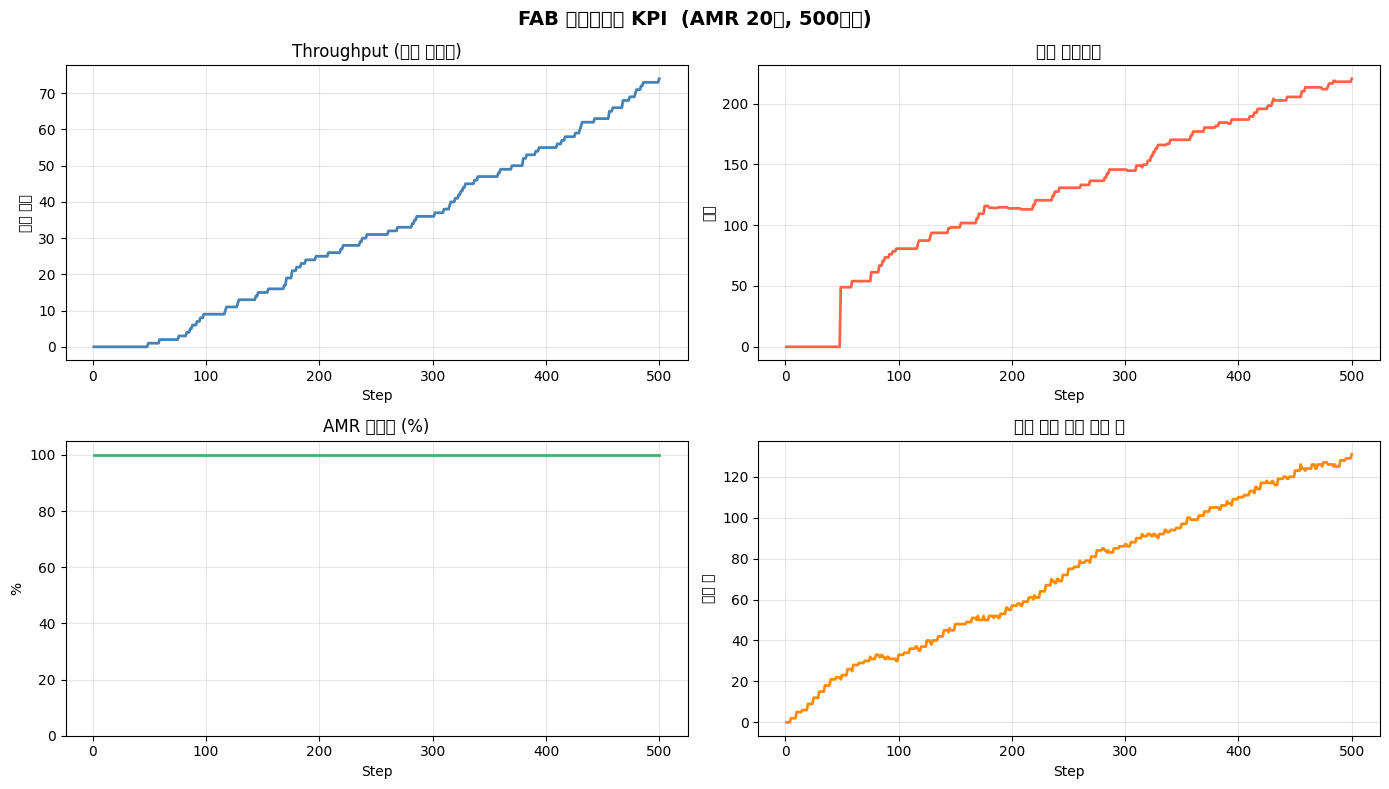

In [16]:
# KPI 시각화

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
steps = [k['step'] for k in kpi_log]

axes[0][0].plot(steps, [k['throughput'] for k in kpi_log],
                color='steelblue', linewidth=2)
axes[0][0].set_title("Throughput (누적 처리량)")
axes[0][0].set_xlabel("Step")
axes[0][0].set_ylabel("처리 건수")
axes[0][0].grid(True, alpha=0.3)

axes[0][1].plot(steps, [k['avg_waiting'] for k in kpi_log],
                color='tomato', linewidth=2)
axes[0][1].set_title("평균 대기시간")
axes[0][1].set_xlabel("Step")
axes[0][1].set_ylabel("스텝")
axes[0][1].grid(True, alpha=0.3)

axes[1][0].plot(steps, [k['utilization'] for k in kpi_log],
                color='mediumseagreen', linewidth=2)
axes[1][0].set_title("AMR 가동률 (%)")
axes[1][0].set_xlabel("Step")
axes[1][0].set_ylabel("%")
axes[1][0].set_ylim(0, 105)
axes[1][0].grid(True, alpha=0.3)

axes[1][1].plot(steps, [k['pending'] for k in kpi_log],
                color='darkorange', linewidth=2)
axes[1][1].set_title("대기 중인 반송 요청 수")
axes[1][1].set_xlabel("Step")
axes[1][1].set_ylabel("요청 수")
axes[1][1].grid(True, alpha=0.3)

plt.suptitle(
    f"FAB 시뮬레이터 KPI  "
    f"(AMR {sim.n_amrs}대, {N_STEPS}스텝)",
    fontsize=14, fontweight='bold'
)
plt.tight_layout()
plt.show()

In [17]:
# 요청 간격 조정 실험

sim = FABSimulator(
    grid_map         = grid_map,
    port_locations   = port_locations,
    n_amrs           = 20,
    request_interval = 15,   # 15스텝마다 요청 생성
    seed             = 42,
)

N_STEPS = 500
kpi_log = []

print("시뮬레이션 시작!")
print(f"AMR {sim.n_amrs}대 | 요청간격: {sim.request_interval}스텝\n")

for step in range(N_STEPS):
    sim.step()
    kpi = sim.get_kpi()
    kpi_log.append(kpi)

    if step % 50 == 0:
        print(f"Step {kpi['step']:4d} | "
              f"처리량: {kpi['throughput']:4d} | "
              f"대기시간: {kpi['avg_waiting']:6.1f} | "
              f"가동률: {kpi['utilization']:5.1f}% | "
              f"대기요청: {kpi['pending']:3d}")

print("\n최종 KPI:")
final = sim.get_kpi()
for k, v in final.items():
    print(f"  {k:15s}: {v}")

시뮬레이션 시작!
AMR 20대 | 요청간격: 15스텝

Step    1 | 처리량:    0 | 대기시간:    0.0 | 가동률: 100.0% | 대기요청:   0
Step   51 | 처리량:    1 | 대기시간:   49.0 | 가동률: 100.0% | 대기요청:   5
Step  101 | 처리량:    9 | 대기시간:   80.7 | 가동률: 100.0% | 대기요청:   6
Step  151 | 처리량:   15 | 대기시간:   98.5 | 가동률: 100.0% | 대기요청:   9
Step  201 | 처리량:   21 | 대기시간:  116.8 | 가동률: 100.0% | 대기요청:  10
Step  251 | 처리량:   29 | 대기시간:  130.5 | 가동률: 100.0% | 대기요청:   7
Step  301 | 처리량:   38 | 대기시간:  147.2 | 가동률: 100.0% | 대기요청:   4
Step  351 | 처리량:   45 | 대기시간:  149.6 | 가동률: 100.0% | 대기요청:   1
Step  401 | 처리량:   55 | 대기시간:  153.8 | 가동률:  90.0% | 대기요청:   0
Step  451 | 처리량:   59 | 대기시간:  153.8 | 가동률: 100.0% | 대기요청:   4

최종 KPI:
  step           : 500
  throughput     : 71
  avg_waiting    : 153.48
  utilization    : 80.0
  pending        : 0
  deadlocks      : 0
  reward         : 633.26


/tmp/ipykernel_1380/3487934238.py:40: UserWarning: Glyph 52376 (\N{HANGUL SYLLABLE CEO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1380/3487934238.py:40: UserWarning: Glyph 47532 (\N{HANGUL SYLLABLE RI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1380/3487934238.py:40: UserWarning: Glyph 44148 (\N{HANGUL SYLLABLE GEON}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1380/3487934238.py:40: UserWarning: Glyph 49688 (\N{HANGUL SYLLABLE SU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1380/3487934238.py:40: UserWarning: Glyph 45572 (\N{HANGUL SYLLABLE NU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1380/3487934238.py:40: UserWarning: Glyph 51201 (\N{HANGUL SYLLABLE JEOG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1380/3487934238.py:40: UserWarning: Glyph 47049 (\N{HANGUL SYLLABLE RYANG}) missing from font(s) DejaVu Sans.
  plt.tight_

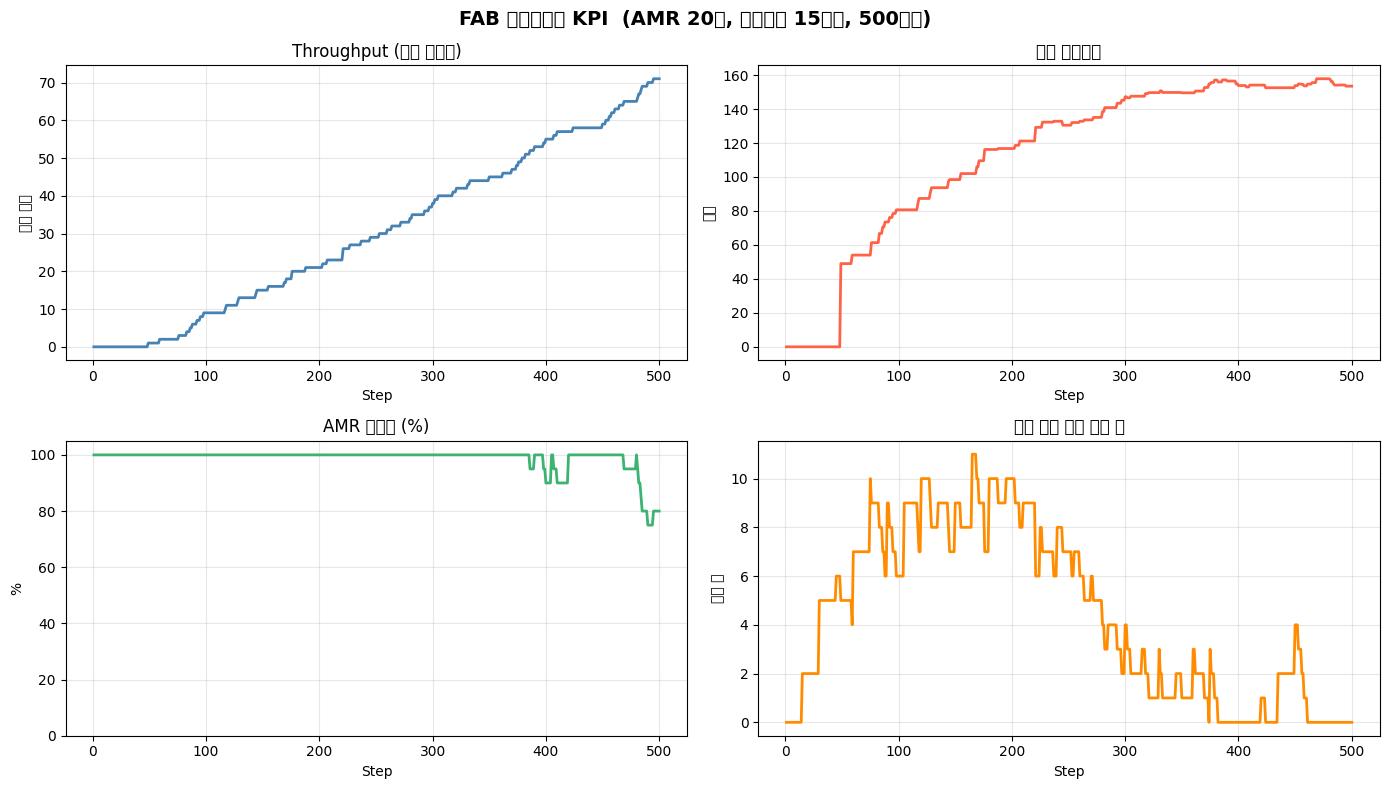

In [18]:
# KPI 시각화

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
steps = [k['step'] for k in kpi_log]

axes[0][0].plot(steps, [k['throughput'] for k in kpi_log],
                color='steelblue', linewidth=2)
axes[0][0].set_title("Throughput (누적 처리량)")
axes[0][0].set_xlabel("Step")
axes[0][0].set_ylabel("처리 건수")
axes[0][0].grid(True, alpha=0.3)

axes[0][1].plot(steps, [k['avg_waiting'] for k in kpi_log],
                color='tomato', linewidth=2)
axes[0][1].set_title("평균 대기시간")
axes[0][1].set_xlabel("Step")
axes[0][1].set_ylabel("스텝")
axes[0][1].grid(True, alpha=0.3)

axes[1][0].plot(steps, [k['utilization'] for k in kpi_log],
                color='mediumseagreen', linewidth=2)
axes[1][0].set_title("AMR 가동률 (%)")
axes[1][0].set_xlabel("Step")
axes[1][0].set_ylabel("%")
axes[1][0].set_ylim(0, 105)
axes[1][0].grid(True, alpha=0.3)

axes[1][1].plot(steps, [k['pending'] for k in kpi_log],
                color='darkorange', linewidth=2)
axes[1][1].set_title("대기 중인 반송 요청 수")
axes[1][1].set_xlabel("Step")
axes[1][1].set_ylabel("요청 수")
axes[1][1].grid(True, alpha=0.3)

plt.suptitle(
    f"FAB 시뮬레이터 KPI  "
    f"(AMR {sim.n_amrs}대, 요청간격 {sim.request_interval}스텝, {N_STEPS}스텝)",
    fontsize=14, fontweight='bold'
)
plt.tight_layout()
plt.show()